In [1]:
# useful additional packages
import matplotlib.pyplot as plt
import numpy as np
import networkx as nx

from qiskit_aer import Aer
from qiskit.tools.visualization import plot_histogram
from qiskit.circuit.library import TwoLocal, EfficientSU2
from qiskit_optimization.applications import Maxcut
from qiskit.algorithms.minimum_eigensolvers import SamplingVQE, NumPyMinimumEigensolver
from qiskit.algorithms.optimizers import SPSA
from qiskit.utils import algorithm_globals
from qiskit.primitives import Sampler
from qiskit_optimization.algorithms import MinimumEigenOptimizer

In [20]:
# Generating a graph of 4 nodes

n = 3  # Number of nodes in graph
m = 4
G1 = nx.Graph()
G1.add_nodes_from(np.arange(0, n, 1))
elist = [(0, 1, 1.0), (0, 2, 1.0), (1, 2, 1.0)]
# tuple is (i,j,weight) where (i,j) is the edge
G1.add_weighted_edges_from(elist)

G2 = nx.Graph()
G2.add_nodes_from(np.arange(0, m, 1))
elist2 = [(0, 1, 1.0), (0, 2, 1.0), (0, 3, 1.0), (1, 2, 1.0), (2, 3, 1.0)]
G2.add_weighted_edges_from(elist2)

colors = ["r" for node in G1.nodes()]
pos = nx.spring_layout(G1)

colors2 = ["b" for node in G2.nodes()]
pos2 = nx.spring_layout(G2)

def draw_graph(G, colors, pos):
    default_axes = plt.axes(frameon=True)
    nx.draw_networkx(G, node_color=colors, node_size=600, alpha=0.8, ax=default_axes, pos=pos)
    edge_labels = nx.get_edge_attributes(G, "weight")
    nx.draw_networkx_edge_labels(G, pos=pos, edge_labels=edge_labels)

def get_weight_matrix(G):
    # Computing the weight matrix from the random graph
    n = G.number_of_nodes()
    w = np.zeros([n, n])
    for i in range(n):
        for j in range(n):
            temp = G.get_edge_data(i, j, default=0)
            if temp != 0:
                w[i, j] = temp["weight"]
    return w

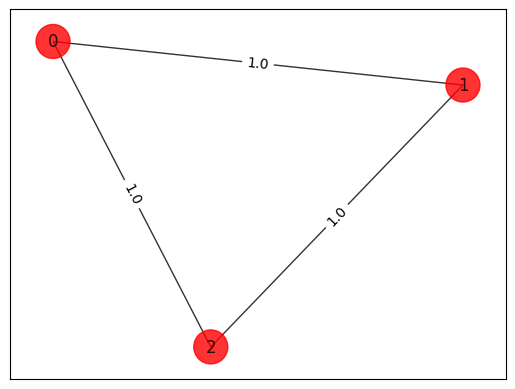

In [10]:
draw_graph(G1, colors, pos)

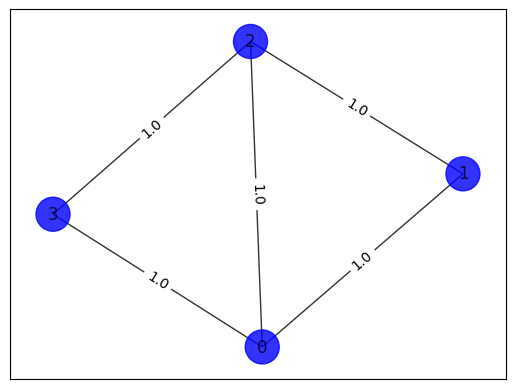

In [11]:
draw_graph(G2, colors2, pos2)

In [22]:
print(get_weight_matrix(G2))

[[0. 1. 1. 1.]
 [1. 0. 1. 0.]
 [1. 1. 0. 1.]
 [1. 0. 1. 0.]]


In [25]:
from qiskit import opflow
from qiskit.quantum_info import Pauli

def cubic_to_hamiltonian(Q):
    # Initialize an empty list to hold the terms of the Hamiltonian
    hamiltonian_terms = []
    
    # Loop through each coefficient in the QUBO problem
    for i in range(len(Q)):
        for j in range(len(Q)):
            for k in range(len(Q)):
                # Get the coefficient for the cubic term
                coeff = Q[i][j][k]
                
                # Create a Pauli term for this coefficient
                pauli_term = Pauli((np.zeros(3), np.array([i==j==k, i==j==k, i==j==k])))
                
                # Add the weighted Pauli term to the list
                hamiltonian_terms.append([coeff, pauli_term])
    
    # Create a WeightedPauliOperator from the list of terms
    hamiltonian = opflow.(hamiltonian_terms)
    
    return hamiltonian

In [26]:
Q = np.ones((2, 2, 2))
print(cubic_to_hamiltonian(Q))

C:\Users\Alexander's Laptop\AppData\Local\Temp\ipykernel_24344\105780582.py:22: DeprecationWarning: The class ``qiskit.opflow.primitive_ops.pauli_op.PauliOp`` is deprecated as of qiskit-terra 0.24.0. It will be removed no earlier than 3 months after the release date. For code migration guidelines, visit https://qisk.it/opflow_migration.
  hamiltonian = opflow.PauliOp(hamiltonian_terms)


TypeError: PauliOp can only be instantiated with Paulis, not <class 'list'>

In [ ]:
from qiskit import Aer
from qiskit.aqua import QuantumInstance
from qiskit_optimization.applications.ising import max_cut
from qiskit.aqua.algorithms import QAOA
from qiskit.aqua.components.optimizers import COBYLA

# Define your cubic problem
# In this case, the problem is a Max-Cut problem for simplicity
w = np.array([[0, 1, 1], [1, 0, 1], [1, 1, 0]])
qubitOp, offset = max_cut.get_operator(w)

# Define a QAOA solver
qaoa = QAOA(qubitOp, COBYLA(), 3)

# Run the QAOA solver
backend = Aer.get_backend('statevector_simulator')
quantum_instance = QuantumInstance(backend, shots=100)
result = qaoa.run(quantum_instance)

# Show the result
print('energy:', result['energy'])
print('time:', result['eval_time'])
print('max-cut objective:', result['energy'] + offset)

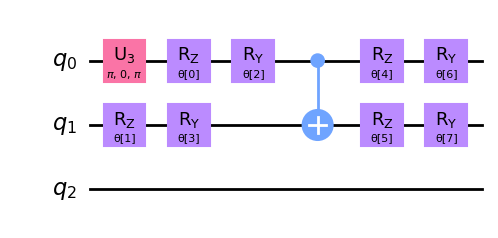

In [41]:
from qiskit import QuantumCircuit
from qiskit.quantum_info import SparsePauliOp
from qiskit.circuit.library import TwoLocal
import numpy as np

theta_list = (3 * np.pi * np.random.rand(1, 8)).tolist()
observable = SparsePauliOp.from_list([("XZX", 1), ("YYY", -3)])

reference_circuit = QuantumCircuit(3)
reference_circuit.x(0)

variational_form = TwoLocal(
    2,
    rotation_blocks=["rz", "ry"],
    entanglement_blocks="cx",
    entanglement="linear",
    reps=1,
)
ansatz = reference_circuit.compose(variational_form)
ansatz.decompose().draw('mpl')

In [1]:
from typing import Dict, List, Optional, Tuple, Union, cast

class CubicProgram:

    def __init__(self, name: str = "") -> None:
        self.linear = []
        self.quadratic = []
        self.cubic = []
        self.num_vars = 0

    def get_num_vars(self):
        return self.num_vars
    
    def set_num_vars(self, n):
        self.num_vars = n

    def set_linear(self, linear_vars_list):
        self.linear = linear_vars_list
    
    def set_quadratic(self, quadratic_vars_list):
        self.quadratic = quadratic_vars_list

    def set_cubic(self, cubic_vars_list):
        self.cubic = cubic_vars_list
    

first_cubic = CubicProgram()
first_cubic.set_num_vars(3)
first_cubic.set_linear([(0, 1)])
first_cubic.set_quadratic([((0, 1), 1)])
first_cubic.set_cubic([((0, 1, 2), 1)])

print(first_cubic.cubic)

[((0, 1, 2), 1)]


In [81]:
test = CubicProgram()
# test.set_num_vars(4)
# test.set_linear([(0, 3.0), (1, 2.0), (2, 3.0), (3, 2.0)])
# test.set_quadratic([((0, 1), -2.0), ((0, 2), -2.0), ((0, 3), -2.0), ((1, 2), -2.0), ((2, 3), -2.0)])
# test.set_cubic([])

test.set_num_vars(12)
test.set_linear([((0,), 4), ((1,), 4), ((2,), 4), ((3,), 4), ((4,), 4), ((5,), 4), ((6,), 4), ((7,), 4), ((8,), 4), ((9,), 4), ((10,), 4), ((11,), 4)])
test.set_quadratic([((0, 0), 1), ((0, 1), 2), ((0, 2), 2), ((4, 4), 1), ((4, 5), 2), ((4, 6), 2), ((8, 8), 1), ((8, 9), 2), ((8, 10), 2), ((1, 1), 1), ((1, 2), 2), ((5, 5), 1), ((5, 6), 2), ((9, 9), 1), ((9, 10), 2), ((2, 2), 1), ((6, 6), 1), ((10, 10), 1), ((0, 3), 1), ((1, 3), 1), ((2, 3), 1), ((4, 7), 1), ((5, 7), 1), ((6, 7), 1), ((8, 11), 1), ((9, 11), 1), ((10, 11), 1), ((0, 5), -12), ((0, 7), -12), ((0, 9), -12), ((0, 11), -12), ((4, 9), -12), ((4, 11), -12), ((1, 7), -12), ((1, 11), -12), ((5, 11), -12), ((2, 5), -12), ((2, 7), -12), ((2, 9), -12), ((2, 11), -12), ((6, 9), -12), ((6, 11), -12)])
test.set_cubic([((0, 1, 1), 3), ((0, 1, 3), 12), ((0, 3, 3), 3), ((0, 5, 5), 3), ((0, 5, 7), 6), ((0, 7, 7), 3), ((0, 9, 9), 3), ((0, 9, 11), 6), ((0, 11, 11), 3), ((1, 1, 4), 3), ((1, 3, 4), 6), ((3, 3, 4), 3), ((4, 5, 5), 3), ((4, 5, 7), 12), ((4, 7, 7), 3), ((4, 9, 9), 3), ((4, 9, 11), 6), ((4, 11, 11), 3), ((1, 1, 8), 3), ((1, 3, 8), 6), ((3, 3, 8), 3), ((5, 5, 8), 3), ((5, 7, 8), 6), ((7, 7, 8), 3), ((8, 9, 9), 3), ((8, 9, 11), 12), ((8, 11, 11), 3), ((1, 3, 3), 3), ((1, 7, 7), 3), ((1, 11, 11), 3), ((3, 3, 5), 3), ((5, 7, 7), 3), ((5, 11, 11), 3), ((3, 3, 9), 3), ((7, 7, 9), 3), ((9, 11, 11), 3), ((1, 1, 2), 3), ((1, 2, 3), 12), ((2, 3, 3), 3), ((2, 5, 5), 3), ((2, 5, 7), 6), ((2, 7, 7), 3), ((2, 9, 9), 3), ((2, 9, 11), 6), ((2, 11, 11), 3), ((1, 1, 6), 3), ((1, 3, 6), 6), ((3, 3, 6), 3), ((5, 5, 6), 3), ((5, 6, 7), 12), ((6, 7, 7), 3), ((6, 9, 9), 3), ((6, 9, 11), 6), ((6, 11, 11), 3), ((1, 1, 10), 3), ((1, 3, 10), 6), ((3, 3, 10), 3), ((5, 5, 10), 3), ((5, 7, 10), 6), ((7, 7, 10), 3), ((9, 9, 10), 3), ((9, 10, 11), 12), ((10, 11, 11), 3), ((0, 0, 1), 3), ((0, 1, 2), 6), ((1, 2, 2), 3), ((1, 4, 4), 3), ((1, 4, 6), 6), ((1, 6, 6), 3), ((1, 8, 8), 3), ((1, 8, 10), 6), ((1, 10, 10), 3), ((0, 0, 5), 3), ((0, 2, 5), 6), ((2, 2, 5), 3), ((4, 4, 5), 3), ((4, 5, 6), 6), ((5, 6, 6), 3), ((5, 8, 8), 3), ((5, 8, 10), 6), ((5, 10, 10), 3), ((0, 0, 9), 3), ((0, 2, 9), 6), ((2, 2, 9), 3), ((4, 4, 9), 3), ((4, 6, 9), 6), ((6, 6, 9), 3), ((8, 8, 9), 3), ((8, 9, 10), 6), ((9, 10, 10), 3), ((0, 0, 3), 3), ((0, 2, 3), 6), ((1, 1, 3), 3), ((2, 2, 3), 3), ((3, 4, 4), 3), ((3, 4, 5), 6), ((3, 4, 6), 6), ((3, 5, 5), 3), ((3, 5, 6), 6), ((3, 6, 6), 3), ((3, 8, 8), 3), ((3, 8, 9), 6), ((3, 8, 10), 6), ((3, 9, 9), 3), ((3, 9, 10), 6), ((3, 10, 10), 3), ((0, 0, 7), 3), ((0, 1, 7), 6), ((0, 2, 7), 6), ((1, 1, 7), 3), ((1, 2, 7), 6), ((2, 2, 7), 3), ((4, 4, 7), 3), ((4, 6, 7), 6), ((5, 5, 7), 3), ((6, 6, 7), 3), ((7, 8, 8), 3), ((7, 8, 9), 6), ((7, 8, 10), 6), ((7, 9, 9), 3), ((7, 9, 10), 6), ((7, 10, 10), 3), ((0, 0, 11), 3), ((0, 1, 11), 6), ((0, 2, 11), 6), ((1, 1, 11), 3), ((1, 2, 11), 6), ((2, 2, 11), 3), ((4, 4, 11), 3), ((4, 5, 11), 6), ((4, 6, 11), 6), ((5, 5, 11), 3), ((5, 6, 11), 6), ((6, 6, 11), 3), ((8, 8, 11), 3), ((8, 10, 11), 6), ((9, 9, 11), 3), ((10, 10, 11), 3)])

# test.set_num_vars(18)
# test.set_linear([((0,), 4), ((1,), 4), ((2,), 4), ((3,), 4), ((4,), 4), ((5,), 4), ((6,), 4), ((7,), 4), ((8,), 4), ((9,), 4), ((10,), 4), ((11,), 4)])
# test.set_quadratic([((0, 0), 1), ((0, 1), 2), ((0, 2), 2), ((4, 4), 1), ((4, 5), 2), ((4, 6), 2), ((8, 8), 1), ((8, 9), 2), ((8, 10), 2), ((1, 1), 1), ((1, 2), 2), ((5, 5), 1), ((5, 6), 2), ((9, 9), 1), ((9, 10), 2), ((2, 2), 1), ((6, 6), 1), ((10, 10), 1), ((0, 3), 1), ((1, 3), 1), ((2, 3), 1), ((4, 7), 1), ((5, 7), 1), ((6, 7), 1), ((8, 11), 1), ((9, 11), 1), ((10, 11), 1), ((0, 6), -12), ((0, 10), -12), ((4, 10), -12), ((1, 4), -12), ((1, 6), -12), ((1, 8), -12), ((1, 10), -12), ((5, 8), -12), ((5, 10), -12)])
# test.set_cubic([((0, 2, 2), 3), ((0, 6, 6), 3), ((0, 10, 10), 3), ((2, 2, 4), 3), ((4, 6, 6), 3), ((4, 10, 10), 3), ((2, 2, 8), 3), ((6, 6, 8), 3), ((8, 10, 10), 3), ((0, 0, 1), 3), ((0, 1, 2), 12), ((1, 2, 2), 3), ((1, 4, 4), 3), ((1, 4, 6), 6), ((1, 6, 6), 3), ((1, 8, 8), 3), ((1, 8, 10), 6), ((1, 10, 10), 3), ((0, 0, 5), 3), ((0, 2, 5), 6), ((2, 2, 5), 3), ((4, 4, 5), 3), ((4, 5, 6), 12), ((5, 6, 6), 3), ((5, 8, 8), 3), ((5, 8, 10), 6), ((5, 10, 10), 3), ((0, 0, 9), 3), ((0, 2, 9), 6), ((2, 2, 9), 3), ((4, 4, 9), 3), ((4, 6, 9), 6), ((6, 6, 9), 3), ((8, 8, 9), 3), ((8, 9, 10), 12), ((9, 10, 10), 3), ((0, 1, 1), 3), ((0, 5, 5), 3), ((0, 9, 9), 3), ((1, 1, 4), 3), ((4, 5, 5), 3), ((4, 9, 9), 3), ((1, 1, 8), 3), ((5, 5, 8), 3), ((8, 9, 9), 3), ((0, 0, 2), 3), ((1, 1, 2), 3), ((2, 4, 4), 3), ((2, 4, 5), 6), ((2, 5, 5), 3), ((2, 8, 8), 3), ((2, 8, 9), 6), ((2, 9, 9), 3), ((0, 0, 6), 3), ((0, 1, 6), 6), ((1, 1, 6), 3), ((4, 4, 6), 3), ((5, 5, 6), 3), ((6, 8, 8), 3), ((6, 8, 9), 6), ((6, 9, 9), 3), ((0, 0, 10), 3), ((0, 1, 10), 6), ((1, 1, 10), 3), ((4, 4, 10), 3), ((4, 5, 10), 6), ((5, 5, 10), 3), ((8, 8, 10), 3), ((9, 9, 10), 3)])

# test.set_num_vars(6)
# test.set_linear([((0,), 0), ((1,), 0), ((2,), 0), ((3,), 0), ((4,), 0), ((5,), 0)])
# test.set_quadratic([((0, 0), 1), ((0, 1), 2), ((3, 3), 1), ((3, 4), 2), ((1, 1), 1), ((4, 4), 1), ((0, 2), 1), ((1, 2), 1), ((3, 5), 1), ((4, 5), 1), ((0, 4), -8), ((2, 4), -8)])
# test.set_cubic([((0, 1, 1), 2), ((0, 4, 4), 2), ((1, 1, 3), 2), ((3, 4, 4), 2), ((1, 1, 2), 2), ((2, 4, 4), 2), ((1, 1, 5), 2), ((4, 4, 5), 2), ((0, 0, 1), 2), ((0, 1, 2), 4), ((1, 2, 2), 2), ((1, 3, 3), 2), ((1, 3, 5), 4), ((1, 5, 5), 2), ((0, 0, 4), 2), ((0, 2, 4), 4), ((2, 2, 4), 2), ((3, 3, 4), 2), ((3, 4, 5), 4), ((4, 5, 5), 2)])

# test.set_num_vars(4)
# test.set_linear([((0,), -4), ((1,), -4), ((2,), -4), ((3,), -4)])
# test.set_quadratic([((0, 0), 2), ((0, 1), 4), ((0, 2), 4), ((0, 3), 4), ((1, 1), 2), ((1, 2), 4), ((1, 3), 4), ((2, 2), 2), ((2, 3), 4), ((3, 3), 2)])
# test.set_cubic([((0, 0, 0), -1), ((0, 0, 1), -1), ((0, 0, 2), -1), ((0, 0, 3), -1), ((0, 1, 1), -1), ((1, 1, 1), -1), ((1, 1, 2), -1), ((1, 1, 3), -1), ((0, 2, 2), -1), ((1, 2, 2), -1), ((2, 2, 2), -1), ((2, 2, 3), -1), ((0, 3, 3), -1), ((1, 3, 3), -1), ((2, 3, 3), -1), ((3, 3, 3), -1)])

# test.set_num_vars(3)
# test.set_linear([((0,), -3), ((1,), -3), ((2,), -3)])
# test.set_quadratic([((0, 0), 2), ((0, 1), 4), ((0, 2), 4), ((1, 1), 2), ((1, 2), 4), ((2, 2), 2)])
# test.set_cubic([((0, 0, 0), -1), ((0, 0, 1), -1), ((0, 0, 2), -1), ((0, 1, 1), -1), ((1, 1, 1), -1), ((1, 1, 2), -1), ((0, 2, 2), -1), ((1, 2, 2), -1), ((2, 2, 2), -1)])

In [63]:
from qiskit_optimization.problems.quadratic_program import QuadraticProgram
from qiskit.quantum_info import Pauli, SparsePauliOp
from qiskit.quantum_info import Pauli
import numpy as np

def to_cubic_ising(cubic_prog: CubicProgram) -> SparsePauliOp:
    num_vars = cubic_prog.get_num_vars()
    zero = np.zeros(num_vars, dtype=bool)
    cubic_list = []

    offset = 0
    sense = 1

    # convert linear parts of the objective function into Hamiltonian.
    for idx, coef in cubic_prog.linear:
        z_p = zero.copy()
        weight = coef*sense / 2
        z_p[idx] = True
        cubic_list.append(SparsePauliOp(Pauli((z_p, zero)), -weight))
        offset += weight

    # convert quadratic parts of the objective function into Hamiltonian.
    for (i, j), coeff in cubic_prog.quadratic:
        weight = coeff*sense / 4

        if (i == j):
            offset += weight
        else:
            z_p = zero.copy()
            z_p[i] = True
            z_p[j] = True
            cubic_list.append(SparsePauliOp(Pauli((z_p, zero)), weight))
        
        z_p = zero.copy()
        z_p[i] = True
        cubic_list.append(SparsePauliOp(Pauli((z_p, zero)), -weight))

        z_p = zero.copy()
        z_p[j] = True
        cubic_list.append(SparsePauliOp(Pauli((z_p, zero)), -weight))

        offset += weight

    # convert cubic parts of the objective function into Hamiltonian.
    for (i, j, k), coeff in cubic_prog.cubic:
        weight = coeff*sense / 8

        # consider cubic terms:
        if i == j and j == k:
            # a*a*a = Ia = a
            z_p[i] = True
            cubic_list.append(SparsePauliOp(Pauli((z_p, zero)), -weight))
        else:
            if i == j and j != k:
                # Then we have something like a^2c = Ic = c (quadratic case where i != j):
                z_p = zero.copy()
                z_p[k] = True
                cubic_list.append(SparsePauliOp(Pauli((z_p, zero)), -weight))
            else:
                if i != j and i == k:
                    # a^2b = Ib = b:
                    z_p = zero.copy()
                    z_p[j] = True
                    cubic_list.append(SparsePauliOp(Pauli((z_p, zero)), -weight))
                else:
                    if i != j and j == k:
                        # aI = a
                        z_p = zero.copy()
                        z_p[i] = True
                        cubic_list.append(SparsePauliOp(Pauli((z_p, zero)), -weight))
                    else:
                        # i != j != k: abc
                        z_p = zero.copy()
                        z_p[i] = True
                        z_p[j] = True
                        z_p[k] = True
                        cubic_list.append(SparsePauliOp(Pauli((z_p, zero)), -weight))


        # consider quadratic terms:
        if (i == j):
            offset += weight
        else:
            z_p = zero.copy()
            z_p[i] = True
            z_p[j] = True
            cubic_list.append(SparsePauliOp(Pauli((z_p, zero)), weight))
        
        if (i == k):
            offset += weight
        else:
            z_p = zero.copy()
            z_p[i] = True
            z_p[k] = True
            cubic_list.append(SparsePauliOp(Pauli((z_p, zero)), weight))
        
        if (j == k):
            offset += weight
        else:
            z_p = zero.copy()
            z_p[j] = True
            z_p[k] = True
            cubic_list.append(SparsePauliOp(Pauli((z_p, zero)), weight))
        
        # consider linear terms
        z_p = zero.copy()
        z_p[i] = True
        cubic_list.append(SparsePauliOp(Pauli((z_p, zero)), -weight))

        z_p = zero.copy()
        z_p[j] = True
        cubic_list.append(SparsePauliOp(Pauli((z_p, zero)), -weight))

        z_p = zero.copy()
        z_p[k] = True
        cubic_list.append(SparsePauliOp(Pauli((z_p, zero)), -weight))

        # consider constant term:
        offset += weight

    # combine all Pauli terms
    print(cubic_list)
    if cubic_list:
        # Remove paulis whose coefficients are zeros.
        qubit_op = sum(cubic_list).simplify(atol=0)
    else:
        # If there is no variable, we set num_nodes=1 so that qubit_op should be an operator.
        # If num_nodes=0, I^0 = 1 (int).
        num_vars = max(1, num_vars)
        qubit_op = SparsePauliOp("I" * num_vars, 0)

    return qubit_op, offset

In [82]:
qubitOp, offset = to_cubic_ising(test)
print("Offset:", offset)
print("Ising Hamiltonian:")
print(str(qubitOp))

[SparsePauliOp(['IIIIIIIIIIIZ'],
              coeffs=[-2.+0.j]), SparsePauliOp(['IIIIIIIIIIZI'],
              coeffs=[-2.+0.j]), SparsePauliOp(['IIIIIIIIIZII'],
              coeffs=[-2.+0.j]), SparsePauliOp(['IIIIIIIIZIII'],
              coeffs=[-2.+0.j]), SparsePauliOp(['IIIIIIIZIIII'],
              coeffs=[-2.+0.j]), SparsePauliOp(['IIIIIIZIIIII'],
              coeffs=[-2.+0.j]), SparsePauliOp(['IIIIIZIIIIII'],
              coeffs=[-2.+0.j]), SparsePauliOp(['IIIIZIIIIIII'],
              coeffs=[-2.+0.j]), SparsePauliOp(['IIIZIIIIIIII'],
              coeffs=[-2.+0.j]), SparsePauliOp(['IIZIIIIIIIII'],
              coeffs=[-2.+0.j]), SparsePauliOp(['IZIIIIIIIIII'],
              coeffs=[-2.+0.j]), SparsePauliOp(['ZIIIIIIIIIII'],
              coeffs=[-2.+0.j]), SparsePauliOp(['IIIIIIIIIIIZ'],
              coeffs=[-0.25+0.j]), SparsePauliOp(['IIIIIIIIIIIZ'],
              coeffs=[-0.25+0.j]), SparsePauliOp(['IIIIIIIIIIZZ'],
              coeffs=[0.5+0.j]), SparsePauliOp(['IIII

In [79]:
from qiskit.quantum_info import Statevector
from qiskit.result import QuasiDistribution
from collections import OrderedDict

def sample_most_likely(
    state_vector: Union[QuasiDistribution, Statevector, np.ndarray, Dict]
) -> np.ndarray:
    """Compute the most likely binary string from state vector.

    Args:
        state_vector: state vector or counts or quasi-probabilities.

    Returns:
        binary string as numpy.ndarray of ints.

    Raises:
        ValueError: if state_vector is not QuasiDistribution, Statevector,
            np.ndarray, or dict.
    """
    if isinstance(state_vector, QuasiDistribution):
        print(1)
        probabilities = state_vector.binary_probabilities()
        binary_string = max(probabilities.items(), key=lambda kv: kv[1])[0]
        x = np.asarray([int(y) for y in reversed(list(binary_string))])
        return x
    elif isinstance(state_vector, Statevector):
        probabilities = state_vector.probabilities()
        print(np.abs(probabilities))
        n = state_vector.num_qubits
        k = np.argmax(np.abs(probabilities))
        print(f"The largest probability: {np.max(np.abs(probabilities))}")
        x = np.zeros(n)
        for i in range(n):
            x[i] = k % 2
            k >>= 1
        return x
    elif isinstance(state_vector, (OrderedDict, dict)):
        print(3)
        # get the binary string with the largest count
        binary_string = max(state_vector.items(), key=lambda kv: kv[1])[0]
        x = np.asarray([int(y) for y in reversed(list(binary_string))])
        return x
    elif isinstance(state_vector, np.ndarray):
        print(4)
        n = int(np.log2(state_vector.shape[0]))
        k = np.argmax(np.abs(state_vector))
        x = np.zeros(n)
        for i in range(n):
            x[i] = k % 2
            k >>= 1
        return x
    else:
        raise ValueError(
            "state vector should be QuasiDistribution, Statevector, ndarray, or dict. "
            f"But it is {type(state_vector)}."
        )

#print(sample_most_likely(result.eigenstate))

In [83]:
from qiskit.algorithms.minimum_eigensolvers import SamplingVQE, NumPyMinimumEigensolver

ee = NumPyMinimumEigensolver()
result = ee.compute_minimum_eigenvalue(qubitOp)

x = sample_most_likely(result.eigenstate)
print("energy:", result.eigenvalue.real)
print("objective:", result.eigenvalue.real + offset)
print("solution:", x)

[0. 0. 0. ... 0. 0. 0.]
The largest probability: 1.0
2084
energy: -102.25
objective: -4.0
solution: [0. 0. 1. 0. 0. 1. 0. 0. 0. 0. 0. 1.]


In [84]:
from qiskit.utils import algorithm_globals
from qiskit.algorithms.optimizers import SPSA, SLSQP
from qiskit.circuit.library import TwoLocal, EfficientSU2
from qiskit.primitives import Sampler
from qiskit.algorithms.minimum_eigensolvers import SamplingVQE, NumPyMinimumEigensolver, VQE
from qiskit.primitives import Estimator 

# algorithm_globals.random_seed = 123
# seed = 10598

# construct SamplingVQE
optimizer = SPSA(maxiter=1000)   # Stochastic gradient decsent optimisation method
# #ry = TwoLocal(qubitOp.num_qubits, "ry", "cz", reps=5, entanglement="linear")
# ry = EfficientSU2(qubitOp.num_qubits, su2_gates="ry", reps=5, entanglement="linear")
# vqe = SamplingVQE(sampler=Sampler(), ansatz=ry, optimizer=optimizer)

# # run SamplingVQE
# result = vqe.compute_minimum_eigenvalue(qubitOp)
# print(result)

estimator = Estimator() 
optimizer = SLSQP() 
# ansatz = TwoLocal(rotation_blocks=["ry", "rz"], entanglement_blocks="cz") 
ansatz = EfficientSU2(qubitOp.num_qubits, su2_gates="ry", reps=5, entanglement="linear")
 
vqe = VQE(estimator, ansatz, optimizer) 
result = vqe.compute_minimum_eigenvalue(operator=qubitOp) 
eigenvalue = result.eigenvalue

# run VQE:
print(result.cost_function_evals)
print(result)
#print(sample_most_likely(result.eigenstate))
print(f"Energy: {result.eigenvalue}")
print(f"Optimal value: {result.eigenvalue + offset}")

c:\Users\Alexander's Laptop\Documents\Computing Stuff\Quantum\.conda\Lib\site-packages\scipy\optimize\_optimize.py:404: RuntimeWarning: Values in x were outside bounds during a minimize step, clipping to bounds
  warnings.warn("Values in x were outside bounds during a "


4169
{   'aux_operators_evaluated': None,
    'cost_function_evals': 4169,
    'eigenvalue': -98.74999906391473,
    'optimal_circuit': <qiskit.circuit.library.n_local.efficient_su2.EfficientSU2 object at 0x00000118856E9A10>,
    'optimal_parameters': {   ParameterVectorElement(θ[6]): 1.570811393555051,
                              ParameterVectorElement(θ[7]): 1.570780301531423,
                              ParameterVectorElement(θ[5]): 1.5707974376609386,
                              ParameterVectorElement(θ[11]): 1.570702840905182,
                              ParameterVectorElement(θ[10]): 3.1413566111512408,
                              ParameterVectorElement(θ[12]): -0.48766239415339663,
                              ParameterVectorElement(θ[9]): 4.197834411782037e-05,
                              ParameterVectorElement(θ[13]): -1.8041648911821488,
                              ParameterVectorElement(θ[19]): 2.689816083239833,
                              ParameterVectorEl

In [68]:
print(result)
#print(sample_most_likely(result.eigenstate))
print(f"Energy: {result.eigenvalue}")
print(f"Optimal value: {result.eigenvalue + offset}")

{   'aux_operators_evaluated': None,
    'cost_function_evals': 1359,
    'eigenvalue': -12.999999626277623,
    'optimal_circuit': <qiskit.circuit.library.n_local.efficient_su2.EfficientSU2 object at 0x0000011886A6B390>,
    'optimal_parameters': {   ParameterVectorElement(θ[4]): -1.5707624879973847,
                              ParameterVectorElement(θ[5]): 0.0974748068595733,
                              ParameterVectorElement(θ[6]): -3.0139137238969838,
                              ParameterVectorElement(θ[3]): -1.778037435671897,
                              ParameterVectorElement(θ[2]): -1.5471670225020253,
                              ParameterVectorElement(θ[0]): -0.13559382668088618,
                              ParameterVectorElement(θ[1]): 1.2290671694544482,
                              ParameterVectorElement(θ[11]): 1.553374828678995,
                              ParameterVectorElement(θ[16]): 1.400924952275652,
                              ParameterVectorElement(

In [80]:
from qiskit import Aer, QuantumCircuit, transpile, assemble

optimal_parameters = result.optimal_parameters
optimal_circuit = ansatz.assign_parameters(optimal_parameters)

# Execute the optimal circuit to obtain the final statevector
backend = Aer.get_backend('statevector_simulator')
final_state = backend.run(transpile(optimal_circuit, backend)).result().get_statevector()

# The optimal eigenstate is directly obtained from the final statevector
optimal_eigenstate = final_state

print("Optimal Eigenstate:", optimal_eigenstate)

print(sample_most_likely(optimal_eigenstate))

Optimal Eigenstate: Statevector([ 2.10610064e-05+0.j,  3.49198185e-06+0.j, -2.05211318e-05+0.j,
             -3.11088843e-06+0.j,  1.25231745e-06+0.j,  3.96497239e-06+0.j,
             -1.75991172e-05+0.j, -9.71302498e-06+0.j, -4.60326114e-05+0.j,
             -2.58657225e-06+0.j,  8.94303685e-06+0.j,  6.01919991e-06+0.j,
             -2.68371147e-06+0.j,  8.97493936e-07+0.j,  1.30592357e-07+0.j,
             -3.43855876e-06+0.j, -6.20353253e-05+0.j, -8.61303197e-06+0.j,
              1.94967309e-05+0.j,  8.72301528e-06+0.j,  9.99999982e-01+0.j,
              1.29606817e-05+0.j,  2.51727599e-06+0.j,  5.05900880e-07+0.j,
              6.63152740e-07+0.j,  3.95224604e-06+0.j,  6.27411855e-07+0.j,
             -1.04487713e-06+0.j, -4.69010380e-09+0.j, -5.83347076e-06+0.j,
              2.84050926e-05+0.j,  1.34603155e-05+0.j, -7.61095387e-06+0.j,
              2.03021522e-06+0.j, -2.41001370e-06+0.j, -2.21574889e-07+0.j,
              5.02337603e-06+0.j,  1.10556136e-05+0.j, -7.96503859e-

In [159]:
def reverse_mapping(mapped_value, m):
    i = mapped_value // m  # Integer division to retrieve the i value
    j = mapped_value % m   # Modulus operation to retrieve the j value

    return i, j

for i in range(6):
    print(f"Node {i} is node: {reverse_mapping(i, 3)}")

Node 0 is node: (0, 0)
Node 1 is node: (0, 1)
Node 2 is node: (0, 2)
Node 3 is node: (1, 0)
Node 4 is node: (1, 1)
Node 5 is node: (1, 2)
